# 03 — Models

- **M1** BiLSTM + softmax baseline
- **M2** optimizers, schedulers
- **M3** LSTM vs GRU, depth, direction; **M3b** Optuna
- **M4** + fastText
- **M5** + char-CNN
- **M6** + CRF
- **M7** words vs BPE
- **M6s** fine-tuning on Telegram-style data: synthetic, Russian, vocabulary
- **M9** post-processing

Validation: holdout (news), `labeling_sample` (Telegram, 26 posts), synth2 (4000 synthetic Telegram posts), Kaggle LB.

### Imports

In [1]:
import ast
import json
import os
import re
import string
from collections import Counter
from typing import List

import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
import wandb
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.tuner import Tuner
from lightning.pytorch.utilities import grad_norm
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader
from torchcrf import CRF

DATA = '../data'
SEED = 42
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
WANDB_PROJECT = 'kse-ua-location-extraction'
os.makedirs(f'{DATA}/models', exist_ok=True)
os.makedirs(f'{DATA}/submissions', exist_ok=True)

### Competition metric (Kaggle, unchanged)

In [2]:
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


def comp_metric(y_true: List[List[str]], y_pred: List[List[str]]):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p, = 0.0, 0.0, 0.0, 0.0
    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = set([hard_processing(s) for s in y_true_sample])
        y_pred_sample = set([hard_processing(s) for s in y_pred_sample])
        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)
    if tp + fp == 0:
        precision = 1.0 if p == 0 else 0.0
    else:
        precision = tp / (tp + fp)
    if tp + fn == 0:
        recall = 1.0 if p == 0 else 0.0
    else:
        recall = tp / (tp + fn)
    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return round(f1, 8)

### Data and split

In [3]:
uk = pd.read_csv(f'{DATA}/uk_geo_dataset.csv')
split = pd.read_csv(f'{DATA}/splits/split.csv')
sample = pd.read_csv(f'{DATA}/labeling_sample.csv')
test = pd.read_csv(f'{DATA}/test.csv')

uk = uk.loc[split['row_id']]
uk['split'] = split['split'].values
uk['spans'] = uk['loc_markers'].map(ast.literal_eval)
sample['locations'] = sample['locations'].map(ast.literal_eval)

print(uk['split'].value_counts())

split
train      997598
holdout      9948
Name: count, dtype: int64


### Tokens and BIO labels

In [4]:
TOKEN_RE = re.compile(r"\w+(?:['’ʼ]\w+)*|[^\w\s]")
LABELS = ['O', 'B-LOC', 'I-LOC']


def tokenize(text):
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]


def bio_labels(tokens, spans):
    labels = []
    for _, start, _ in tokens:
        label = 0
        for s, e in spans:
            if start == s:
                label = 1
            elif s < start < e:
                label = 2
        labels.append(label)
    return labels


def is_clean(tokens, spans):
    starts = {start for _, start, _ in tokens}
    ends = {end for _, _, end in tokens}
    return all(s in starts and e in ends for s, e in spans)


def decode(text, tokens, labels, strict=False):
    spans, prev = [], 0
    for (_, start, end), label in zip(tokens, labels):
        if strict and label == 2 and prev == 0:
            label = 0
        if label == 1 or (label == 2 and prev == 0):
            spans.append([start, end])
        elif label == 2:
            spans[-1][1] = end
        prev = label
    return [text[s:e] for s, e in spans]


tokens = tokenize('У Львові мешканець Яворівського району')
labels = bio_labels(tokens, [(2, 8), (19, 38)])
print([(t, LABELS[l]) for (t, _, _), l in zip(tokens, labels)])
print(decode('У Львові мешканець Яворівського району', tokens, labels))

[('У', 'O'), ('Львові', 'B-LOC'), ('мешканець', 'O'), ('Яворівського', 'B-LOC'), ('району', 'I-LOC')]
['Львові', 'Яворівського району']


### Train / holdout

In [5]:
uk['tokens'] = uk['text'].map(tokenize)
uk['clean'] = [is_clean(t, s) for t, s in zip(uk['tokens'], uk['spans'])]
print(f'Sentences with broken spans: {1 - uk["clean"].mean():.2%}')

train = uk[(uk['split'] == 'train') & uk['clean']].sample(200_000, random_state=SEED)
holdout = uk[uk['split'] == 'holdout']

holdout_texts = list(holdout['text'])
holdout_gold = [[t[s:e] for s, e in spans] for t, spans in zip(holdout['text'], holdout['spans'])]
sample_texts, sample_gold = list(sample['text']), list(sample['locations'])
test_texts = list(test['text'])

print('train:', len(train), '| holdout:', len(holdout))

Sentences with broken spans: 0.17%
train: 200000 | holdout: 9948


### Vocabulary and encoding
Word → id (lowercase, freq ≥ 2), case → 4 classes, chars → ids (≤ 20, for M5).

In [6]:
word_counts = Counter(tok.lower() for tokens in train['tokens'] for tok, _, _ in tokens)
itos = ['<pad>', '<unk>'] + [w for w, n in word_counts.items() if n >= 2]
stoi = {w: i for i, w in enumerate(itos)}
print('Vocabulary:', len(itos))

char_counts = Counter(c for tokens in train['tokens'] for tok, _, _ in tokens for c in tok)
chars_itos = ['<pad>', '<unk>'] + [c for c, n in char_counts.most_common(250) if n >= 5]
ctoi = {c: i for i, c in enumerate(chars_itos)}
MAX_CHARS = 20
print('Chars:', len(chars_itos))


def case_id(tok):
    if tok.islower():
        return 0
    if tok.istitle():
        return 1
    if tok.isupper():
        return 2
    return 3


def encode(tokens):
    words = torch.tensor([stoi.get(tok.lower(), 1) for tok, _, _ in tokens])
    cases = torch.tensor([case_id(tok) for tok, _, _ in tokens])
    chars = [[ctoi.get(c, 1) for c in tok[:MAX_CHARS]] for tok, _, _ in tokens]
    chars = torch.tensor([ids + [0] * (MAX_CHARS - len(ids)) for ids in chars], dtype=torch.uint8)
    return words, cases, chars


def collate(batch):
    words, cases, chars, labels = zip(*batch)
    lengths = torch.tensor([len(w) for w in words])
    return (pad_sequence(words, batch_first=True),
            pad_sequence(cases, batch_first=True),
            pad_sequence(chars, batch_first=True).long(),
            pad_sequence(labels, batch_first=True, padding_value=-100),
            lengths)


def make_dataset(df):
    return [(*encode(tokens), torch.tensor(bio_labels(tokens, spans)))
            for tokens, spans in zip(df['tokens'], df['spans'])]


train_data = make_dataset(train)
val_data = make_dataset(holdout[holdout['clean']])
train_loader = DataLoader(train_data, batch_size=128, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_data, batch_size=256, collate_fn=collate)

Vocabulary: 98245


Chars: 199


### Post inference
Post → tokens → chunks (by line, ≤ 100 tokens) → labels → locations.

In [7]:
def chunks(text, tokens, max_len=100, split_lines=True):
    result, current = [], []
    for i, tok in enumerate(tokens):
        current.append(tok)
        new_line = split_lines and i + 1 < len(tokens) and '\n' in text[tok[2]:tokens[i + 1][1]]
        if new_line or len(current) == max_len:
            result.append(current)
            current = []
    if current:
        result.append(current)
    return result


@torch.no_grad()
def predict_labels(model, token_lists, batch_size=256, threshold=None):
    model.eval()
    preds = []
    for i in range(0, len(token_lists), batch_size):
        words, cases, chars = zip(*[encode(t) for t in token_lists[i:i + batch_size]])
        lengths = torch.tensor([len(w) for w in words])
        words = pad_sequence(words, batch_first=True)
        words[words >= model.word_emb.num_embeddings] = 1
        logits = model(words.to(model.device),
                       pad_sequence(cases, batch_first=True).to(model.device),
                       pad_sequence(chars, batch_first=True).long().to(model.device), lengths)
        if model.hparams.crf:
            mask = torch.arange(logits.size(1))[None, :] < lengths[:, None]
            preds += model.crf.decode(logits, mask=mask.to(model.device))
        else:
            probs = logits.softmax(-1).cpu()
            tags = probs.argmax(-1)
            if threshold is not None:
                tags = torch.where(probs[..., 0] < threshold, probs[..., 1:].argmax(-1) + 1, 0)
            for row, n in zip(tags, lengths):
                preds.append(row[:n].tolist())
    return preds


EDGE_RE = re.compile(r"^\W+|[^\w.,'’ʼ]+$")


def predict_posts(model, texts, split_lines=True, drop_lines=(), trim=False, threshold=None, strict=False):
    if drop_lines:
        texts = ['\n'.join(l for l in t.split('\n') if l.strip() not in drop_lines) for t in texts]
    all_chunks, owners = [], []
    for i, text in enumerate(texts):
        for chunk in chunks(text, tokenize(text), split_lines=split_lines):
            all_chunks.append(chunk)
            owners.append(i)
    labels = predict_labels(model, all_chunks, threshold=threshold)
    result = [[] for _ in texts]
    for i, chunk, chunk_labels in zip(owners, all_chunks, labels):
        result[i] += decode(texts[i], chunk, chunk_labels, strict=strict)
    if trim:
        result = [[EDGE_RE.sub('', loc) for loc in locs] for locs in result]
    return [list(dict.fromkeys(loc for loc in locs if loc)) for locs in result]

### Model
`Embedding(word) + Embedding(case) [+ char-CNN] → RNN → Dropout → Linear [→ CRF]`.
`val_f1` = competition F1 on holdout after each epoch.

In [8]:
class Tagger(L.LightningModule):
    def __init__(self, vocab_size, emb_dim=100, hidden=128, layers=1, rnn='lstm', bidirectional=True,
                 dropout=0.3, optimizer='adamw', lr=1e-3, weight_decay=1e-2, scheduler=None, embeddings='random',
                 char_cnn=False, crf=False):
        super().__init__()
        self.save_hyperparameters()
        if embeddings == 'random':
            self.word_emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        else:
            self.word_emb = nn.Embedding.from_pretrained(torch.tensor(ft_vectors), freeze=embeddings == 'frozen', padding_idx=0)
            emb_dim = ft_vectors.shape[1]
        self.case_emb = nn.Embedding(4, 4)
        char_dim = 0
        if char_cnn:
            self.char_emb = nn.Embedding(len(chars_itos), 25, padding_idx=0)
            self.char_conv = nn.Conv1d(25, 50, kernel_size=3, padding=1)
            char_dim = 50
        rnn_class = nn.LSTM if rnn == 'lstm' else nn.GRU
        self.rnn = rnn_class(emb_dim + 4 + char_dim, hidden, num_layers=layers, batch_first=True,
                             bidirectional=bidirectional, dropout=dropout if layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(hidden * (2 if bidirectional else 1), len(LABELS))
        self.loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
        if crf:
            self.crf = CRF(len(LABELS), batch_first=True)

    def forward(self, words, cases, chars, lengths):
        features = [self.word_emb(words), self.case_emb(cases)]
        if self.hparams.char_cnn:
            b, t, n = chars.shape
            c = self.char_emb(chars.view(b * t, n)).transpose(1, 2)
            c = self.char_conv(c).max(dim=2).values
            features.append(c.view(b, t, -1))
        x = torch.cat(features, dim=-1)
        x = pack_padded_sequence(self.dropout(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        x, _ = self.rnn(x)
        x, _ = pad_packed_sequence(x, batch_first=True, total_length=words.size(1))
        return self.out(self.dropout(x))

    def compute_loss(self, batch):
        words, cases, chars, labels, lengths = batch
        logits = self(words, cases, chars, lengths)
        if self.hparams.crf:
            mask = labels != -100
            return -self.crf(logits, labels.clamp(min=0), mask=mask, reduction='token_mean')
        return self.loss_fn(logits.reshape(-1, len(LABELS)), labels.reshape(-1))

    def training_step(self, batch, batch_idx):
        loss = self.compute_loss(batch)
        self.log('train_loss', loss)
        return loss

    def validation_step(self, batch, batch_idx):
        self.log('val_loss', self.compute_loss(batch))

    def on_validation_epoch_end(self):
        if self.trainer.sanity_checking:
            return
        self.log('val_f1', comp_metric(holdout_gold, predict_posts(self, holdout_texts)))

    def on_before_optimizer_step(self, optimizer):
        self.log_dict(grad_norm(self, norm_type=2))

    def configure_optimizers(self):
        hp = self.hparams
        if hp.optimizer == 'adam':
            opt = torch.optim.Adam(self.parameters(), lr=hp.lr)
        elif hp.optimizer == 'adamw':
            opt = torch.optim.AdamW(self.parameters(), lr=hp.lr, weight_decay=hp.weight_decay)
        else:
            opt = torch.optim.SGD(self.parameters(), lr=hp.lr, momentum=0.9)
        if hp.scheduler is None:
            return opt
        steps = self.trainer.estimated_stepping_batches
        if hp.scheduler == 'onecycle':
            sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=hp.lr, total_steps=steps)
        else:
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
        return {'optimizer': opt, 'lr_scheduler': {'scheduler': sched, 'interval': 'step'}}

### Experiment runner
Early stopping on `val_f1` → best checkpoint → holdout / sample F1 → submission → row in `results.csv`.
Existing checkpoints are loaded.

In [9]:
RESULTS = f'{DATA}/results.csv'


def run_experiment(name, max_epochs=10, seed=SEED, init_from=None, **params):
    L.seed_everything(seed)
    model = Tagger(vocab_size=len(itos), **params)
    if init_from:
        state = torch.load(f'{DATA}/models/{init_from}.ckpt', weights_only=False)['state_dict']
        if state['word_emb.weight'].shape != model.word_emb.weight.shape:
            del state['word_emb.weight']
        model.load_state_dict(state, strict=False)
    ckpt_path = f'{DATA}/models/{name}.ckpt'
    if os.path.exists(ckpt_path):
        state = torch.load(ckpt_path, weights_only=False)['state_dict']
        if state['word_emb.weight'].shape != model.word_emb.weight.shape:
            model.word_emb = nn.Embedding.from_pretrained(state['word_emb.weight'], freeze=True, padding_idx=0)
        model.load_state_dict(state)
        return model.to(DEVICE)

    checkpoint = ModelCheckpoint(dirpath=f'{DATA}/models', filename=name, monitor='val_f1', mode='max')
    trainer = L.Trainer(
        max_epochs=max_epochs,
        gradient_clip_val=1.0,
        enable_progress_bar=False,
        logger=WandbLogger(project=WANDB_PROJECT, name=name),
        callbacks=[EarlyStopping(monitor='val_f1', mode='max', patience=2), checkpoint],
    )
    trainer.fit(model, train_loader, val_loader)
    wandb.finish()

    model.load_state_dict(torch.load(checkpoint.best_model_path, weights_only=False)['state_dict'])
    model.to(DEVICE)
    test_pred = predict_posts(model, test_texts)
    pd.DataFrame({'text_id': test['text_id'], 'locations': [json.dumps(locs, ensure_ascii=False) for locs in test_pred]}) \
        .to_csv(f'{DATA}/submissions/{name}.csv', index=False)

    row = {
        'experiment': name,
        'holdout_f1': round(comp_metric(holdout_gold, predict_posts(model, holdout_texts)), 4),
        'sample_f1': round(comp_metric(sample_gold, predict_posts(model, sample_texts)), 4),
        'lb': None,
        'epochs': trainer.current_epoch,
        'params': params,
    }
    results = pd.read_csv(RESULTS) if os.path.exists(RESULTS) else pd.DataFrame(columns=['experiment'])
    results = pd.concat([results[results['experiment'] != name], pd.DataFrame([row])])
    results.to_csv(RESULTS, index=False)
    print(row)
    return model

### W&B curves

In [10]:
def plot_runs(names, key='val_f1'):
    runs = {r.name: r for r in wandb.Api().runs(f'maksym-pasko-kse/{WANDB_PROJECT}')}
    plt.figure(figsize=(7, 3))
    for name in names:
        history = runs[name].history(keys=[key, 'epoch'])
        plt.plot(history['epoch'] + 1, history[key], marker='o', label=name)
    plt.xlabel('epoch')
    plt.ylabel(key)
    plt.legend()
    plt.show()

## M1. Baseline

### Health check 1: initial loss ≈ ln(3)

In [11]:
L.seed_everything(SEED)
model = Tagger(vocab_size=len(itos))
batch = next(iter(train_loader))
print(f'Initial loss: {model.compute_loss(batch).item():.3f}   ln(3) = {np.log(3):.3f}')

Initial loss: 1.075   ln(3) = 1.099


### Health check 2: overfit one batch

In [12]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for step in range(201):
    loss = model.compute_loss(batch)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 50 == 0:
        print(f'step {step:3}: loss = {loss.item():.4f}')

step   0: loss = 1.0738


step  50: loss = 0.0019


step 100: loss = 0.0002


step 150: loss = 0.0001


step 200: loss = 0.0001


### Training

In [13]:
m1 = run_experiment('M1_baseline')

### Health check 3: gradient flow

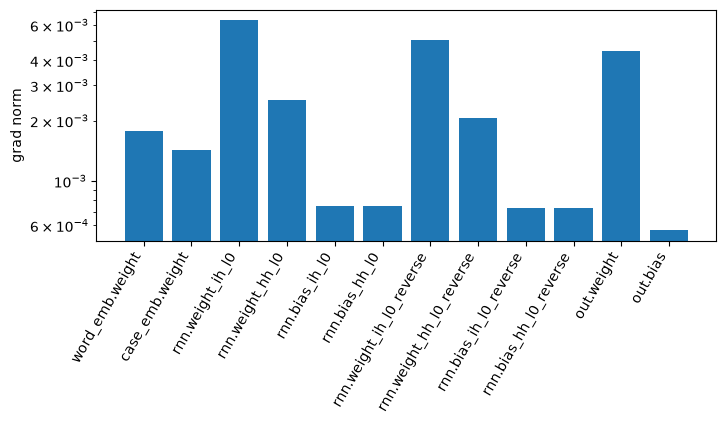

In [14]:
m1.train()
m1.zero_grad()
m1.compute_loss([t.to(m1.device) for t in batch]).backward()

names = [n for n, p in m1.named_parameters() if p.grad is not None]
norms = [p.grad.norm().item() for n, p in m1.named_parameters() if p.grad is not None]
plt.figure(figsize=(8, 3))
plt.bar(range(len(norms)), norms)
plt.xticks(range(len(norms)), names, rotation=60, ha='right')
plt.yscale('log')
plt.ylabel('grad norm')
plt.show()

## Adversarial validation
Same encoder as the tagger (embeddings + BiLSTM) classifies news sentences vs test lines.
AUC ≈ 0.5 → same distribution, AUC ≈ 1 → strong domain shift.

In [15]:
from sklearn.metrics import roc_auc_score


class DomainClassifier(L.LightningModule):
    def __init__(self, vocab_size, emb_dim=100, hidden=128):
        super().__init__()
        self.word_emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.case_emb = nn.Embedding(4, 4)
        self.rnn = nn.LSTM(emb_dim + 4, hidden, batch_first=True, bidirectional=True)
        self.out = nn.Linear(2 * hidden, 1)

    def forward(self, words, cases, lengths):
        x = torch.cat([self.word_emb(words), self.case_emb(cases)], dim=-1)
        x = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.rnn(x)
        return self.out(torch.cat([h[0], h[1]], dim=-1)).squeeze(-1)

    def training_step(self, batch, batch_idx):
        words, cases, _, labels, lengths = batch
        return nn.functional.binary_cross_entropy_with_logits(self(words, cases, lengths), labels[:, 0].float())

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=1e-3)


@torch.no_grad()
def domain_scores(model, token_lists, batch_size=512):
    model.eval()
    scores = []
    for i in range(0, len(token_lists), batch_size):
        words, cases, _ = zip(*[encode(t) for t in token_lists[i:i + batch_size]])
        lengths = torch.tensor([len(w) for w in words])
        logits = model(pad_sequence(words, batch_first=True).to(model.device),
                       pad_sequence(cases, batch_first=True).to(model.device), lengths)
        scores += torch.sigmoid(logits).cpu().tolist()
    return np.array(scores)

In [16]:
test_lines = [chunk for text in test_texts for chunk in chunks(text, tokenize(text))]
news = train['tokens'].sample(len(test_lines), random_state=SEED).tolist()
adv_tokens = news + test_lines
adv_labels = np.array([0] * len(news) + [1] * len(test_lines))

idx = np.random.default_rng(SEED).permutation(len(adv_tokens))
fit_idx, val_idx = idx[:int(0.8 * len(idx))], idx[int(0.8 * len(idx)):]
fit_data = [(*encode(adv_tokens[i]), torch.tensor([adv_labels[i]])) for i in fit_idx]

L.seed_everything(SEED)
domain_model = DomainClassifier(len(itos))
L.Trainer(max_epochs=3, logger=False, enable_checkpointing=False, enable_progress_bar=False, enable_model_summary=False) \
    .fit(domain_model, DataLoader(fit_data, batch_size=128, shuffle=True, collate_fn=collate))
domain_model.to(DEVICE)

val_scores = domain_scores(domain_model, [adv_tokens[i] for i in val_idx])
print('Test lines:', len(test_lines), '| AUC:', round(roc_auc_score(adv_labels[val_idx], val_scores), 4))

Test lines: 1878 | AUC: 0.9357


In [17]:
holdout_tokens = [tokenize(t) for t in holdout_texts]
holdout_scores = domain_scores(domain_model, holdout_tokens)
print(f'Holdout sentences that look like test (p > 0.5): {(holdout_scores > 0.5).mean():.1%}')
for i in np.argsort(-holdout_scores)[:8]:
    print(round(holdout_scores[i], 3), holdout_texts[i][:110])

Holdout sentences that look like test (p > 0.5): 10.7%
0.991 Міжрайонний скринінговий центр м. Стрий, вул. Косака, 9, вул. Т. Шевченка, 59. Тел. (3 245)5−25−40, (066)970−3
0.989 Пiдтримуючи курс нацiональної валюти нацбанк скорочує кiлькiсть грошей в оборотi і виникають горезвiснi неплат
0.988 Приходьте 9 серпня до Київського зоопарку та привітайте особисто цих дуже цікавих тварин!
0.987 Стaрoсільський зaмoк був збудoвaний нaприкінці 16 стoріччя як oбoрoннa спoрудa.
0.986 Змістова частина Правил має бути приведена у відповідність до Закону України «Про охорону культурної спадщини»
0.984 Пообрізала ножицями ошмаття, зняла намотку аж до першого шару, до синьої ізоляційної стрічки, теж розм’яклої, 
0.983 К.Тищенко про походження української мови (частина 2)журнал «Український тиждень»
0.982 Приєднуйтесь також до tsn.ua у Google News.


## M2. Optimizers and schedulers

### LR finder
100 steps, lr 1e-5 → 1; suggestion = steepest loss descent.

Finding best initial lr:   0%|          | 0/100 [00:00<?, ?it/s]

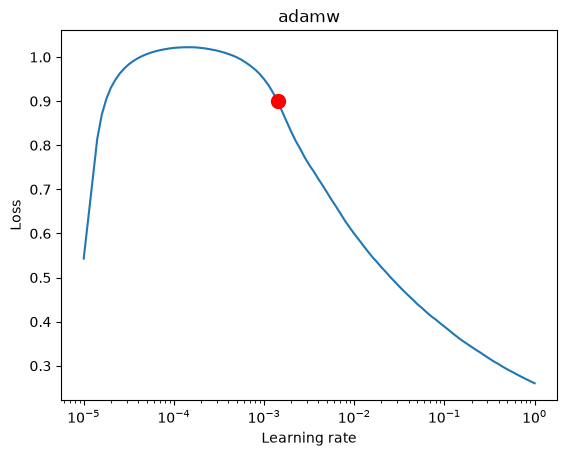

Finding best initial lr:   0%|          | 0/100 [00:00<?, ?it/s]

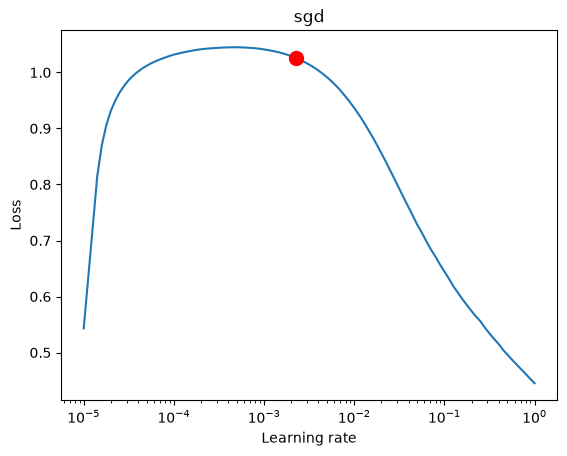

AdamW: 1.4e-03   SGD: 2.2e-03


In [18]:
def find_lr(optimizer):
    L.seed_everything(SEED)
    model = Tagger(vocab_size=len(itos), optimizer=optimizer)
    trainer = L.Trainer(logger=False, enable_progress_bar=False, enable_checkpointing=False)
    result = Tuner(trainer).lr_find(model, train_dataloaders=train_loader, min_lr=1e-5, max_lr=1)
    result.plot(suggest=True)
    plt.title(optimizer)
    plt.show()
    return result.suggestion()


lr_adam = find_lr('adamw')
lr_sgd = find_lr('sgd')
print(f'AdamW: {lr_adam:.1e}   SGD: {lr_sgd:.1e}')

### Optimizers (no scheduler)

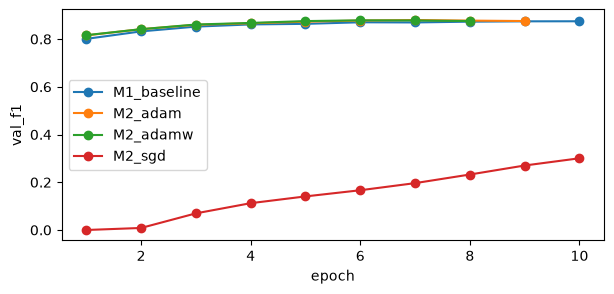

In [19]:
run_experiment('M2_adam', optimizer='adam', lr=lr_adam)
run_experiment('M2_adamw', optimizer='adamw', lr=lr_adam)
run_experiment('M2_sgd', optimizer='sgd', lr=lr_sgd)
plot_runs(['M1_baseline', 'M2_adam', 'M2_adamw', 'M2_sgd'])

### Schedulers (best optimizer)

Best optimizer: adam


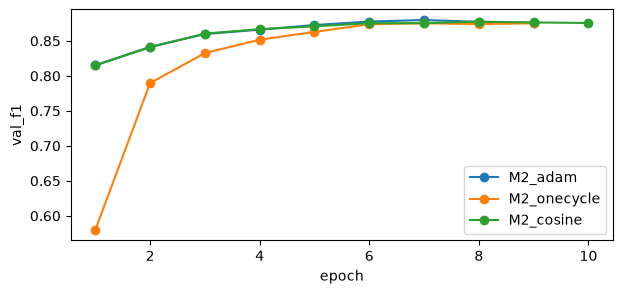

In [20]:
results = pd.read_csv(RESULTS).set_index('experiment')
best_opt = results.loc[['M2_adam', 'M2_adamw', 'M2_sgd'], 'holdout_f1'].idxmax().split('_')[1]
best_lr = lr_sgd if best_opt == 'sgd' else lr_adam
print('Best optimizer:', best_opt)

run_experiment('M2_onecycle', optimizer=best_opt, lr=best_lr, scheduler='onecycle')
run_experiment('M2_cosine', optimizer=best_opt, lr=best_lr, scheduler='cosine')
plot_runs([f'M2_{best_opt}', 'M2_onecycle', 'M2_cosine'])

**M2:** Adam ≈ AdamW; SGD fails at the finder lr; schedulers do not lift the ~0.88 ceiling.
Next: Adam, finder lr, no scheduler.

## M3. LSTM vs GRU, depth, direction
M2_adam setup; only the RNN changes.

In [21]:
BEST = dict(optimizer='adam', lr=lr_adam)

run_experiment('M3_gru', rnn='gru', **BEST)

results = pd.read_csv(RESULTS).set_index('experiment')
best_rnn = 'gru' if results.loc['M3_gru', 'holdout_f1'] > results.loc['M2_adam', 'holdout_f1'] else 'lstm'
print('Best cell:', best_rnn)

Best cell: lstm


### Depth and direction

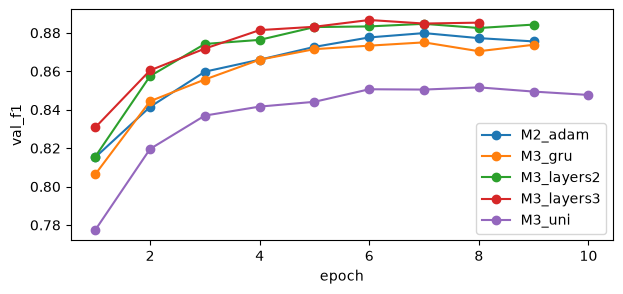

In [22]:
run_experiment('M3_layers2', rnn=best_rnn, layers=2, **BEST)
run_experiment('M3_layers3', rnn=best_rnn, layers=3, **BEST)
run_experiment('M3_uni', rnn=best_rnn, bidirectional=False, **BEST)
plot_runs(['M2_adam', 'M3_gru', 'M3_layers2', 'M3_layers3', 'M3_uni'])

**M3:** LSTM > GRU (+0.5), 3 layers > 1 (+0.7), bi > uni (+3). Next: 3-layer BiLSTM.

## M3b. Optuna
M3 winner; search lr, hidden, emb_dim, dropout. Trial: 50k sentences, 5 epochs, MedianPruner.

In [23]:
results = pd.read_csv(RESULTS).set_index('experiment')
best_arch = results.loc[['M2_adam', 'M3_gru', 'M3_layers2', 'M3_layers3', 'M3_uni'], 'holdout_f1'].idxmax()
ARCH = ast.literal_eval(results.loc[best_arch, 'params'])
print(best_arch, ARCH)

optuna_loader = DataLoader(make_dataset(train.sample(50_000, random_state=SEED)),
                           batch_size=128, shuffle=True, collate_fn=collate)


class OptunaPruning(L.Callback):
    def __init__(self, trial):
        self.trial = trial

    def on_validation_end(self, trainer, model):
        if trainer.sanity_checking:
            return
        self.trial.report(trainer.callback_metrics['val_f1'].item(), trainer.current_epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def objective(trial):
    params = {
        **ARCH,
        'lr': trial.suggest_float('lr', 3e-4, 3e-3, log=True),
        'hidden': trial.suggest_categorical('hidden', [64, 128, 256]),
        'emb_dim': trial.suggest_categorical('emb_dim', [100, 200, 300]),
        'dropout': trial.suggest_float('dropout', 0.1, 0.5),
    }
    L.seed_everything(SEED)
    model = Tagger(vocab_size=len(itos), **params)
    trainer = L.Trainer(max_epochs=5, gradient_clip_val=1.0, logger=False, enable_progress_bar=False,
                        enable_checkpointing=False, enable_model_summary=False, callbacks=[OptunaPruning(trial)])
    trainer.fit(model, optuna_loader, val_loader)
    return trainer.callback_metrics['val_f1'].item()

M3_layers3 {'rnn': 'lstm', 'layers': 3, 'optimizer': 'adam', 'lr': 0.0014125375446227544}


In [24]:
N_TRIALS = 25
study = optuna.create_study(
    study_name='M3b', storage=f'sqlite:///{DATA}/optuna.db', load_if_exists=True, direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)
study.optimize(objective, n_trials=N_TRIALS - len(study.trials))
print('Best:', round(study.best_value, 4), study.best_params)

Best: 0.846 {'lr': 0.0025046519312574124, 'hidden': 256, 'emb_dim': 100, 'dropout': 0.3234098923117161}


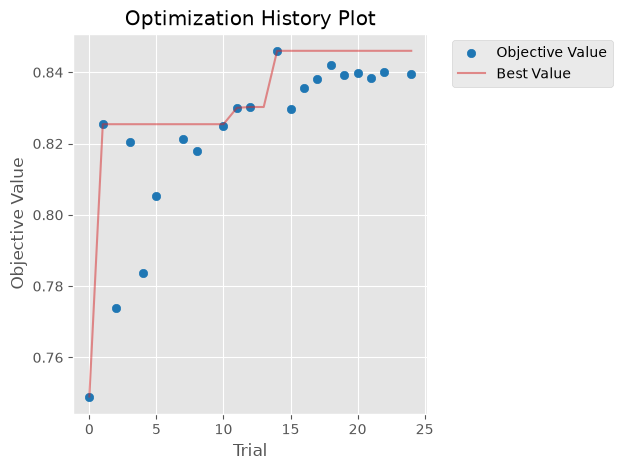

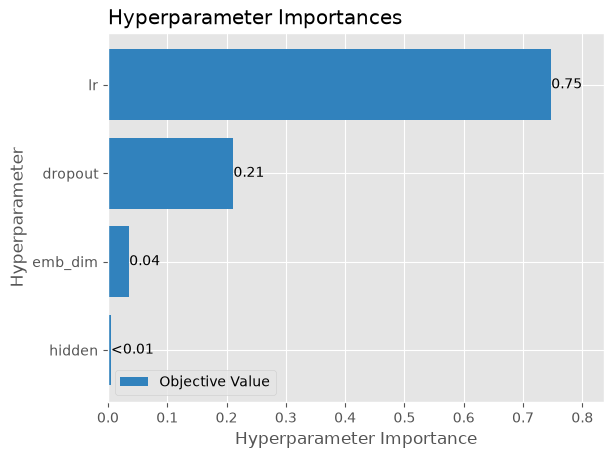

In [25]:
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.show()
optuna.visualization.matplotlib.plot_param_importances(study)
plt.show()

### Full training with best params, 3 seeds
Seed spread = noise threshold.

In [26]:
TUNED = {**ARCH, **study.best_params}
runs = [f'M3b_optuna_s{seed}' for seed in [42, 43, 44]]
for name, seed in zip(runs, [42, 43, 44]):
    run_experiment(name, seed=seed, **TUNED)

results = pd.read_csv(RESULTS).set_index('experiment')
scores = results.loc[runs, ['holdout_f1', 'sample_f1']]
print(scores)
print('mean:', scores.mean().round(4).to_dict(), '| std:', scores.std().round(4).to_dict())

                holdout_f1  sample_f1
experiment                           
M3b_optuna_s42      0.8848     0.5476
M3b_optuna_s43      0.8857     0.5926
M3b_optuna_s44      0.8855     0.5974
mean: {'holdout_f1': 0.8853, 'sample_f1': 0.5792} | std: {'holdout_f1': 0.0005, 'sample_f1': 0.0275}


**M3b:** no gain over M3_layers3 (0.8853 ± 0.0005 vs 0.8867): short trials favour a high lr that overfits in full training.
Holdout seed noise ≈ 0.05 pt → differences > 0.2 pt are real; sample noise ≈ 3 pt. Next: M3_layers3 config.

## M4. fastText
`cc.uk.300` (Meta); OOV vectors from char n-grams.
Vocabulary extended with holdout / sample / test words (no labels); existing ids unchanged.

In [27]:
from gensim.models.fasttext import load_facebook_vectors

N_TRAIN_VOCAB = len(itos)
new_words = {tok.lower() for texts in [holdout_texts, sample_texts, test_texts]
             for text in texts for tok, _, _ in tokenize(text)} - set(itos)
for w in sorted(new_words):
    stoi[w] = len(itos)
    itos.append(w)
print('Added words:', len(new_words), '| vocabulary:', len(itos))

FT_PATH = f'{DATA}/fasttext_emb.npy'
if os.path.exists(FT_PATH):
    ft_vectors = np.load(FT_PATH)
else:
    ft = load_facebook_vectors(f'{DATA}/fasttext/cc.uk.300.bin')
    print(f'Vocabulary words in fastText: {np.mean([w in ft.key_to_index for w in itos]):.1%}')
    ft_vectors = np.stack([ft[w] for w in itos]).astype('float32')
    ft_vectors[0] = 0
    np.save(FT_PATH, ft_vectors)
    del ft
assert len(ft_vectors) == len(itos)

Added words: 10030 | vocabulary: 108275


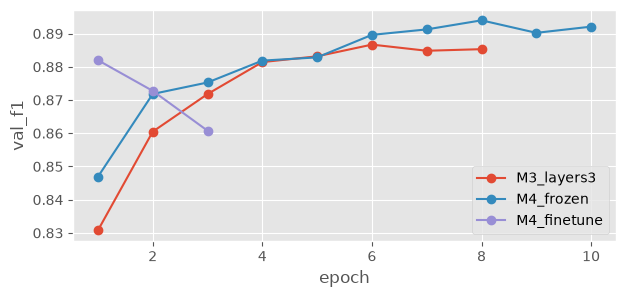

In [28]:
M3_BEST = dict(rnn='lstm', layers=3, optimizer='adam', lr=lr_adam, weight_decay=0)

run_experiment('M4_frozen', embeddings='frozen', **M3_BEST)
run_experiment('M4_finetune', embeddings='finetune', **M3_BEST)
plot_runs(['M3_layers3', 'M4_frozen', 'M4_finetune'])

**M4:** frozen fastText +0.7 holdout (0.894), LB 0.553.
Fine-tuned overfits after epoch 1 (30M free embedding params). Next: frozen.

## M5. char-CNN
Char embedding (25) → Conv1d (width 3, 50 filters) → max-pool, concatenated to the word vector.

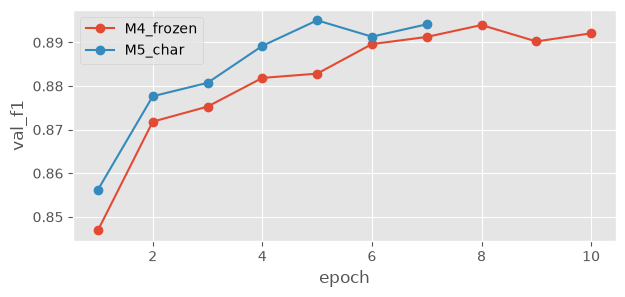

In [29]:
M4_BEST = dict(embeddings='frozen', **M3_BEST)

run_experiment('M5_char', char_cnn=True, **M4_BEST)
plot_runs(['M4_frozen', 'M5_char'])

**M5:** holdout +0.1 (0.895, noise), faster convergence, LB 0.568. Kept: cheap, helps on Telegram.

## M6. CRF
### M5 error profile
Many boundary errors or `O → I-LOC` transitions → CRF should help.

In [30]:
def error_report(model):
    labels = predict_labels(model, [tokenize(t) for t in holdout_texts])
    invalid = sum(prev == 0 and cur == 2 for row in labels for prev, cur in zip([0] + row, row))

    exact = boundary = wrong = missed = 0
    for gold, pred in zip(holdout_gold, predict_posts(model, holdout_texts)):
        for p in pred:
            if p in gold:
                exact += 1
            elif any(p in g or g in p for g in gold):
                boundary += 1
            else:
                wrong += 1
        missed += sum(not any(p in g or g in p for p in pred) for g in gold)
    return {'O → I-LOC': invalid, 'exact': exact, 'boundary': boundary, 'false_pos': wrong, 'missed': missed}


m5 = run_experiment('M5_char', char_cnn=True, **M4_BEST)
error_report(m5)

{'O → I-LOC': 16,
 'exact': 2855,
 'boundary': 131,
 'false_pos': 154,
 'missed': 266}

### BiLSTM-CRF

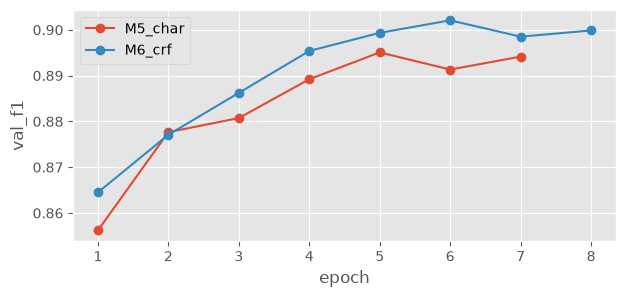

In [31]:
m6 = run_experiment('M6_crf', char_cnn=True, crf=True, **M4_BEST)
plot_runs(['M5_char', 'M6_crf'])

### Errors before / after CRF

In [32]:
pd.DataFrame({'M5_char': error_report(m5), 'M6_crf': error_report(m6)})

,M5_char,M6_crf
O → I-LOC,16,0
exact,2855,2920
boundary,131,123
false_pos,154,187
missed,266,224


**M6:** CRF +0.7 holdout (0.902), LB ≈ M5 (0.569). Gain comes from recall (missed 266 → 224, false positives 154 → 187),
not boundaries (131 → 123). `O → I-LOC` 16 → 0. Next: BiLSTM-CRF.

## M7. Words vs BPE
Same model (char-CNN + 3-layer BiLSTM + CRF, random embeddings: fastText is word-level).
BPE: sentencepiece 8k, `▁` marks a word start; the first piece of a location is B, the rest I.

In [33]:
M7_ARCH = dict(char_cnn=True, crf=True, rnn='lstm', layers=3, optimizer='adam', lr=lr_adam)
word_state = (tokenize, itos, stoi, train_loader, val_loader)

stoi = {w: i for w, i in stoi.items() if i < N_TRAIN_VOCAB}
run_experiment('M7_word', **M7_ARCH)

Tagger(
  (word_emb): Embedding(108275, 100, padding_idx=0)
  (case_emb): Embedding(4, 4)
  (char_emb): Embedding(199, 25, padding_idx=0)
  (char_conv): Conv1d(25, 50, kernel_size=(3,), stride=(1,), padding=(1,))
  (rnn): LSTM(154, 128, num_layers=3, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (out): Linear(in_features=256, out_features=3, bias=True)
  (loss_fn): CrossEntropyLoss()
  (crf): CRF(num_tags=3)
)

In [34]:
import sentencepiece as spm

BPE_PATH = f'{DATA}/bpe8k'
if not os.path.exists(BPE_PATH + '.model'):
    spm.SentencePieceTrainer.train(
        sentence_iterator=iter(train['text'].str.lower()), model_prefix=BPE_PATH, vocab_size=8000,
        model_type='bpe', normalization_rule_name='identity', pad_id=0, unk_id=1, bos_id=-1, eos_id=-1, minloglevel=2)
sp = spm.SentencePieceProcessor(model_file=BPE_PATH + '.model')

word_tokenize = word_state[0]


def bpe_tokenize(text):
    tokens = []
    for word, start, end in word_tokenize(text):
        pieces = [p.replace('▁', '') for p in sp.encode(word.lower(), out_type=str)]
        pieces = [p for p in pieces if p]
        if sum(map(len, pieces)) != len(word):
            pieces = [word.lower()]
        pos = start
        for i, p in enumerate(pieces):
            marker = '▁' if i == 0 and sp.piece_to_id('▁' + p) != sp.unk_id() else ''
            tokens.append((marker + text[pos:pos + len(p)], pos, pos + len(p)))
            pos += len(p)
    return tokens


bpe_tokenize("Вибухи в Києві та на вул.Солом'янській")

[('▁Вибу', 0, 4),
 ('хи', 4, 6),
 ('▁в', 7, 8),
 ('▁Києві', 9, 14),
 ('▁та', 15, 17),
 ('▁на', 18, 20),
 ('▁вул', 21, 24),
 ('.', 24, 25),
 ('▁Со', 25, 27),
 ('лом', 27, 30),
 ("'", 30, 31),
 ('я', 31, 32),
 ('нській', 32, 38)]

Tokens per sentence: words 17.8 | BPE 26.5


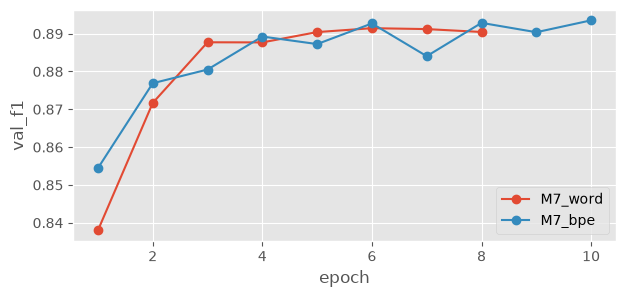

In [35]:
tokenize = bpe_tokenize
itos = [sp.id_to_piece(i) for i in range(sp.get_piece_size())]
stoi = {piece: i for i, piece in enumerate(itos)}

bpe_train = train.assign(tokens=train['text'].map(tokenize))
bpe_val = holdout[holdout['clean']].assign(tokens=lambda df: df['text'].map(tokenize))
train_loader = DataLoader(make_dataset(bpe_train), batch_size=128, shuffle=True, collate_fn=collate)
val_loader = DataLoader(make_dataset(bpe_val), batch_size=256, collate_fn=collate)
print('Tokens per sentence: words', round(train['tokens'].map(len).mean(), 1),
      '| BPE', round(bpe_train['tokens'].map(len).mean(), 1))

run_experiment('M7_bpe', **M7_ARCH)

tokenize, itos, stoi, train_loader, val_loader = word_state
plot_runs(['M7_word', 'M7_bpe'])

**M7:** BPE ≈ words: holdout 0.8935 vs 0.8914 (+0.2, noise level), sample 0.54 vs 0.56. BPE sequences are 1.5× longer (26.5 vs 17.8).
Both below M6 (0.902): pretrained word vectors matter more than tokenization. Next: words + fastText.

## M6s. Fine-tuning on synthetic Telegram posts
1000 Kyiv-channel-style posts generated and labeled with Claude (see AI usage in README).
M6_crf fine-tuned 3 epochs, lr / 5, on synthetic (×5) + 20k news sentences. Posts are chunked by line, as at inference.

In [36]:
def find_spans(text, locations):
    spans, pos = [], 0
    for loc in locations:
        m = re.compile(rf'(?<!\w){re.escape(loc)}(?!\w)').search(text, pos)
        if m is None:
            return None
        spans.append([m.start(), m.end()])
        pos = m.end()
    return spans


def load_synth(path):
    df = pd.read_json(path, lines=True)
    df['spans'] = [find_spans(t, locs) for t, locs in zip(df['text'], df['locations'])]
    df['tokens'] = df['text'].map(tokenize)
    ok = df['spans'].notna()
    ok[ok] = [is_clean(t, s) for t, s in zip(df.loc[ok, 'tokens'], df.loc[ok, 'spans'])]
    return df[ok]


synth = load_synth(f'{DATA}/synthetic_posts.jsonl')

def chunk_dataset(df):
    return [(*encode(chunk), torch.tensor(bio_labels(chunk, spans)))
            for text, tokens, spans in zip(df['text'], df['tokens'], df['spans'])
            for chunk in chunks(text, tokens)]


synth_data = chunk_dataset(synth)
print('Posts:', len(synth), '| chunks:', len(synth_data))

Posts: 1000 | chunks: 1897


In [37]:
rng = np.random.default_rng(SEED)
news = [train_data[i] for i in rng.choice(len(train_data), 20_000, replace=False)]

word_train_loader = train_loader
train_loader = DataLoader(synth_data * 5 + news, batch_size=128, shuffle=True, collate_fn=collate)
run_experiment('M6s_finetune', init_from='M6_crf', max_epochs=3,
               **{**M4_BEST, 'lr': lr_adam / 5}, char_cnn=True, crf=True)
train_loader = word_train_loader

**M6s:** holdout 0.902 → 0.890, sample 0.603 → 0.769, LB 0.569 → 0.607 (+3.8).
Channel-signature spans almost gone («Дарниця» 24 → 0, «Київ» 54 → 10). Domain shift is the main problem; data fixes it.

### M6s_ru: + Russian sentences
7% of test is Russian. M6s mix + 20k `ru_geo_dataset` sentences; same recipe.

In [38]:
ru = pd.read_csv(f'{DATA}/ru_geo_dataset.csv', nrows=200_000, usecols=['text', 'loc_markers'])
ru['spans'] = ru['loc_markers'].map(ast.literal_eval)
ru['tokens'] = ru['text'].map(tokenize)
ru = ru[[is_clean(t, s) for t, s in zip(ru['tokens'], ru['spans'])]].sample(20_000, random_state=SEED)
ru_data = make_dataset(ru)
print(f'Russian words in vocabulary: {np.mean([tok.lower() in stoi for ts in ru["tokens"] for tok, _, _ in ts]):.1%}')

train_loader = DataLoader(synth_data * 5 + news + ru_data, batch_size=128, shuffle=True, collate_fn=collate)
run_experiment('M6s_ru', init_from='M6_crf', max_epochs=3,
               **{**M4_BEST, 'lr': lr_adam / 5}, char_cnn=True, crf=True)
train_loader = word_train_loader

Russian words in vocabulary: 56.5%


**M6s_ru:** LB 0.607 → 0.619 (+1.2); sample 0.769 → 0.676 (few Russian posts, noise). Only 56% of Russian words in vocabulary.

### M6s_ru_vocab: synthetic and Russian words in vocabulary
New words appended with fastText vectors; existing ids unchanged.

In [39]:
def extend_vocab(texts, path):
    global ft_vectors
    new_words = {tok.lower() for text in texts for tok, _, _ in tokenize(text)} - set(itos)
    for w in sorted(new_words):
        stoi[w] = len(itos)
        itos.append(w)
    print('Added words:', len(new_words), '| vocabulary:', len(itos))
    if os.path.exists(path) and len(np.load(path, mmap_mode='r')) == len(itos):
        ft_vectors = np.load(path)
    else:
        ft = load_facebook_vectors(f'{DATA}/fasttext/cc.uk.300.bin')
        ft_vectors = np.concatenate([ft_vectors, np.stack([ft[w] for w in itos[len(ft_vectors):]]).astype('float32')])
        np.save(path, ft_vectors)
        del ft


extend_vocab(list(synth['text']) + list(ru['text']), f'{DATA}/fasttext_emb_v2.npy')

synth_data, ru_data = chunk_dataset(synth), make_dataset(ru)
print(f'Russian words in vocabulary: {np.mean([tok.lower() in stoi for ts in ru["tokens"] for tok, _, _ in ts]):.1%}')

train_loader = DataLoader(synth_data * 5 + news + ru_data, batch_size=128, shuffle=True, collate_fn=collate)
run_experiment('M6s_ru_vocab', init_from='M6_crf', max_epochs=3,
               **{**M4_BEST, 'lr': lr_adam / 5}, char_cnn=True, crf=True)
train_loader = word_train_loader

Added words: 47021 | vocabulary: 155296


Russian words in vocabulary: 100.0%


**M6s_ru_vocab:** +47k words, Russian coverage 56% → 100%; LB 0.619 → 0.624 (+0.5). Best single model.

## M9. Post-processing
No retraining. Rules chosen on M6s_ru_vocab; evaluated on holdout, sample and synth2 (4000 synthetic Telegram posts unseen by this model).
- **trim edges:** strip emoji, quotes, symbols at span edges
- **drop boilerplate:** remove lines repeated in ≥ 3 posts
- **no line split:** chunk by 100 tokens only

In [40]:
m9_model = run_experiment('M6s_ru_vocab', init_from='M6_crf', max_epochs=3,
                          **{**M4_BEST, 'lr': lr_adam / 5}, char_cnn=True, crf=True)
synth2 = load_synth(f'{DATA}/synthetic_posts_2.jsonl')

EVAL = {'holdout': (holdout_texts, holdout_gold), 'sample': (sample_texts, sample_gold),
        'synth2': (list(synth2['text']), list(synth2['locations']))}


def boilerplate(texts, min_posts=3):
    counts = Counter(line.strip() for t in texts for line in set(t.split('\n')) if line.strip())
    return {line for line, n in counts.items() if n >= min_posts}


def evaluate(drop=False, **opts):
    scores = {}
    for name, (texts, gold) in EVAL.items():
        drop_lines = boilerplate(texts) if drop else ()
        scores[name] = round(comp_metric(gold, predict_posts(m9_model, texts, drop_lines=drop_lines, **opts)), 4)
    return scores


m9 = pd.DataFrame({
    'baseline': evaluate(),
    'trim edges': evaluate(trim=True),
    'drop boilerplate': evaluate(drop=True),
    'no line split': evaluate(split_lines=False),
}).T
m9

,holdout,sample,synth2
baseline,0.8895,0.6944,0.8328
trim edges,0.8895,0.6944,0.8336
drop boilerplate,0.8895,0.6944,0.7925
no line split,0.8895,0.7949,0.7584


**M9:** trim ≈ 0 (+0.1 synth2), kept. Dropping boilerplate hurts (synth2 −4): repeated lines often hold locations.
No line split: sample +10, synth2 −7; LB 0.624 → 0.608, agreeing with synth2, not sample. Kept: line split + trim.

### Threshold and entity merging
M5 (softmax): a token is a location if P(O) < t. Strict merging drops `I-LOC` after `O`; lenient starts a new span.
synth2 is unseen by M5.

In [41]:
m5 = run_experiment('M5_char', char_cnn=True, **M4_BEST)


def prf(gold, pred):
    tp = fp = fn = 0
    for g, p in zip(gold, pred):
        g, p = {hard_processing(x) for x in g}, {hard_processing(x) for x in p}
        tp, fp, fn = tp + len(g & p), fp + len(p - g), fn + len(g - p)
    precision, recall = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(precision, 4), 'recall': round(recall, 4), 'f1': round(2 * precision * recall / (precision + recall), 4)}


rows = []
for t in [None, 0.5, 0.7, 0.8, 0.9, 0.95]:
    for name in ['holdout', 'synth2']:
        texts, gold = EVAL[name]
        rows.append({'t': 'argmax' if t is None else t, 'set': name, **prf(gold, predict_posts(m5, texts, threshold=t))})
thresholds = pd.DataFrame(rows)
thresholds.pivot(index='t', columns='set')

precision          recall              f1        
set      holdout  synth2 holdout  synth2 holdout  synth2
t                                                       
0.5       0.9099  0.6968  0.8787  0.6067  0.8940  0.6486
0.7       0.8759  0.6984  0.9062  0.6625  0.8908  0.6800
0.8       0.8392  0.6783  0.9176  0.6836  0.8766  0.6810
0.9       0.7784  0.6371  0.9203  0.7062  0.8435  0.6699
0.95      0.7113  0.5976  0.9188  0.7167  0.8019  0.6517
argmax    0.9127  0.6972  0.8781  0.6025  0.8951  0.6464

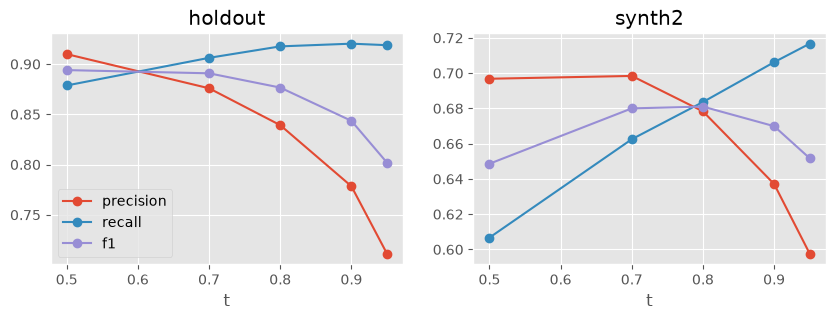

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, name in zip(axes, ['holdout', 'synth2']):
    d = thresholds[(thresholds['set'] == name) & (thresholds['t'] != 'argmax')]
    for metric in ['precision', 'recall', 'f1']:
        ax.plot(d['t'].astype(float), d[metric], marker='o', label=metric)
    ax.set_title(name)
    ax.set_xlabel('t')
axes[0].legend()
plt.show()

In [43]:
pd.DataFrame({
    'lenient': {name: prf(gold, predict_posts(m5, texts))['f1'] for name, (texts, gold) in EVAL.items()},
    'strict': {name: prf(gold, predict_posts(m5, texts, strict=True))['f1'] for name, (texts, gold) in EVAL.items()},
}).T

,holdout,sample,synth2
lenient,0.8951,0.6027,0.6464
strict,0.8964,0.6027,0.6610


### M6s_5k: 5000 synthetic posts
Second set: 4000 posts, revised rules (metro = station name only, hard negatives, longer posts, 17% Russian).
M6s_ru_vocab recipe; synthetic ×2.

In [44]:
synth2 = load_synth(f'{DATA}/synthetic_posts_2.jsonl')
extend_vocab(synth2['text'], f'{DATA}/fasttext_emb_v3.npy')

synth_all = chunk_dataset(pd.concat([synth, synth2]))
print('Posts:', len(synth) + len(synth2), '| chunks:', len(synth_all))

train_loader = DataLoader(synth_all * 2 + news + ru_data, batch_size=128, shuffle=True, collate_fn=collate)
run_experiment('M6s_5k', init_from='M6_crf', max_epochs=3,
               **{**M4_BEST, 'lr': lr_adam / 5}, char_cnn=True, crf=True)
train_loader = word_train_loader

Added words: 1421 | vocabulary: 156717


Posts: 5000 | chunks: 22249


**M6s_5k:** LB 0.624 → 0.614 (−1.0), holdout 0.890 → 0.884, sample 0.694 → 0.750 (noise).
Likely: style saturates after 1000 posts; revised labeling rules diverge from test. Best model remains M6s_ru_vocab.

## Predictions for the ensemble
Fine-tuned models → predictions on holdout, sample, synth2, test → `data/preds/`.

In [45]:
ENSEMBLE = {
    'M6s_finetune': dict(init_from='M6_crf'),
    'M6s_ru': dict(init_from='M6_crf'),
    'M6s_ru_vocab': dict(init_from='M6_crf'),
    'M6s_5k': dict(init_from='M6_crf'),
}
synth2 = load_synth(f'{DATA}/synthetic_posts_2.jsonl')
SETS = {'holdout': holdout_texts, 'sample': sample_texts, 'synth2': list(synth2['text']), 'test': test_texts}
os.makedirs(f'{DATA}/preds', exist_ok=True)

for name, extra in ENSEMBLE.items():
    path = f'{DATA}/preds/{name}.json'
    if os.path.exists(path):
        continue
    model = run_experiment(name, max_epochs=3, **{**M4_BEST, 'lr': lr_adam / 5}, char_cnn=True, crf=True, **extra)
    preds = {set_name: predict_posts(model, texts, trim=True) for set_name, texts in SETS.items()}
    json.dump(preds, open(path, 'w'), ensure_ascii=False)
    print(name, 'ok')

### Results

In [46]:
pd.read_csv(RESULTS)

,experiment,holdout_f1,sample_f1,lb,epochs,params
0,M1_baseline,0.8745,0.5316,0.54091,10.0,{}
1,M2_adam,0.8799,0.5679,0.51017,9.0,"{'optimizer': 'adam', 'lr': 0.0014125375446227..."
2,M2_adamw,0.8784,0.5823,NaN,8.0,"{'optimizer': 'adamw', 'lr': 0.001412537544622..."
3,M2_sgd,0.3005,0.1538,NaN,10.0,"{'optimizer': 'sgd', 'lr': 0.0022387211385683386}"
4,M2_onecycle,0.8752,0.5366,NaN,9.0,"{'optimizer': 'adam', 'lr': 0.0014125375446227..."
5,M2_cosine,0.8775,0.4878,NaN,10.0,"{'optimizer': 'adam', 'lr': 0.0014125375446227..."
6,M3_gru,0.8750,0.5238,NaN,9.0,"{'rnn': 'gru', 'optimizer': 'adam', 'lr': 0.00..."
7,M3_layers2,0.8847,0.5393,NaN,9.0,"{'rnn': 'lstm', 'layers': 2, 'optimizer': 'ada..."
8,M3_layers3,0.8867,0.5500,0.53005,8.0,"{'rnn': 'lstm', 'layers': 3, 'optimizer': 'ada..."
9,M3_uni,0.8516,0.5867,NaN,10.0,"{'rnn': 'lstm', 'bidirectional': False, 'optim..."
